<a href="https://colab.research.google.com/github/shahaanabbas-13/Quantum-Diabetes-Prediction/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 — Exploratory Data Analysis
**Purpose:** inspect the original Pima dataset without modifying it. Run cells from top to bottom.

In [1]:
# If needed in Colab, run once:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

In [2]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
DATA_PATH = Path("../dataset/diabetes.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/content/diabetes.csv")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
df.info()

Shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
display(df.describe().T)
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


Missing values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicate rows: 0


In [4]:
assert df.shape == (768, 9), "Check that the original 768-row, 9-column dataset was loaded."
assert "Outcome" in df.columns and set(df["Outcome"].unique()).issubset({0,1})
print(df["Outcome"].value_counts())
print((df["Outcome"].value_counts(normalize=True)*100).round(2))

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


,zero_count,zero_percent
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


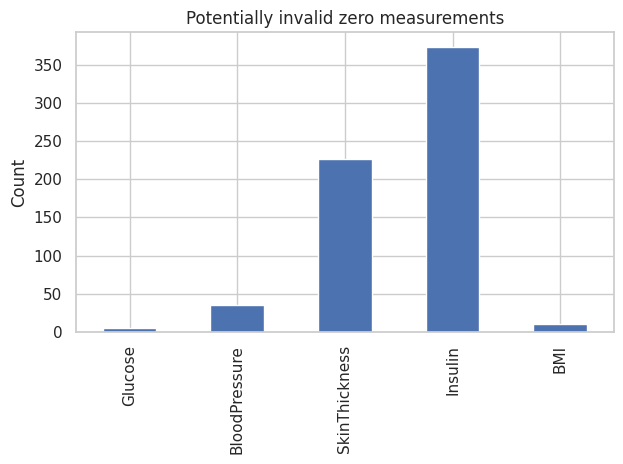

In [5]:
invalid_zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_summary = pd.DataFrame({
    "zero_count": (df[invalid_zero_cols] == 0).sum(),
    "zero_percent": (df[invalid_zero_cols] == 0).mean()*100
})
display(zero_summary)
zero_summary["zero_count"].plot(kind="bar", title="Potentially invalid zero measurements")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

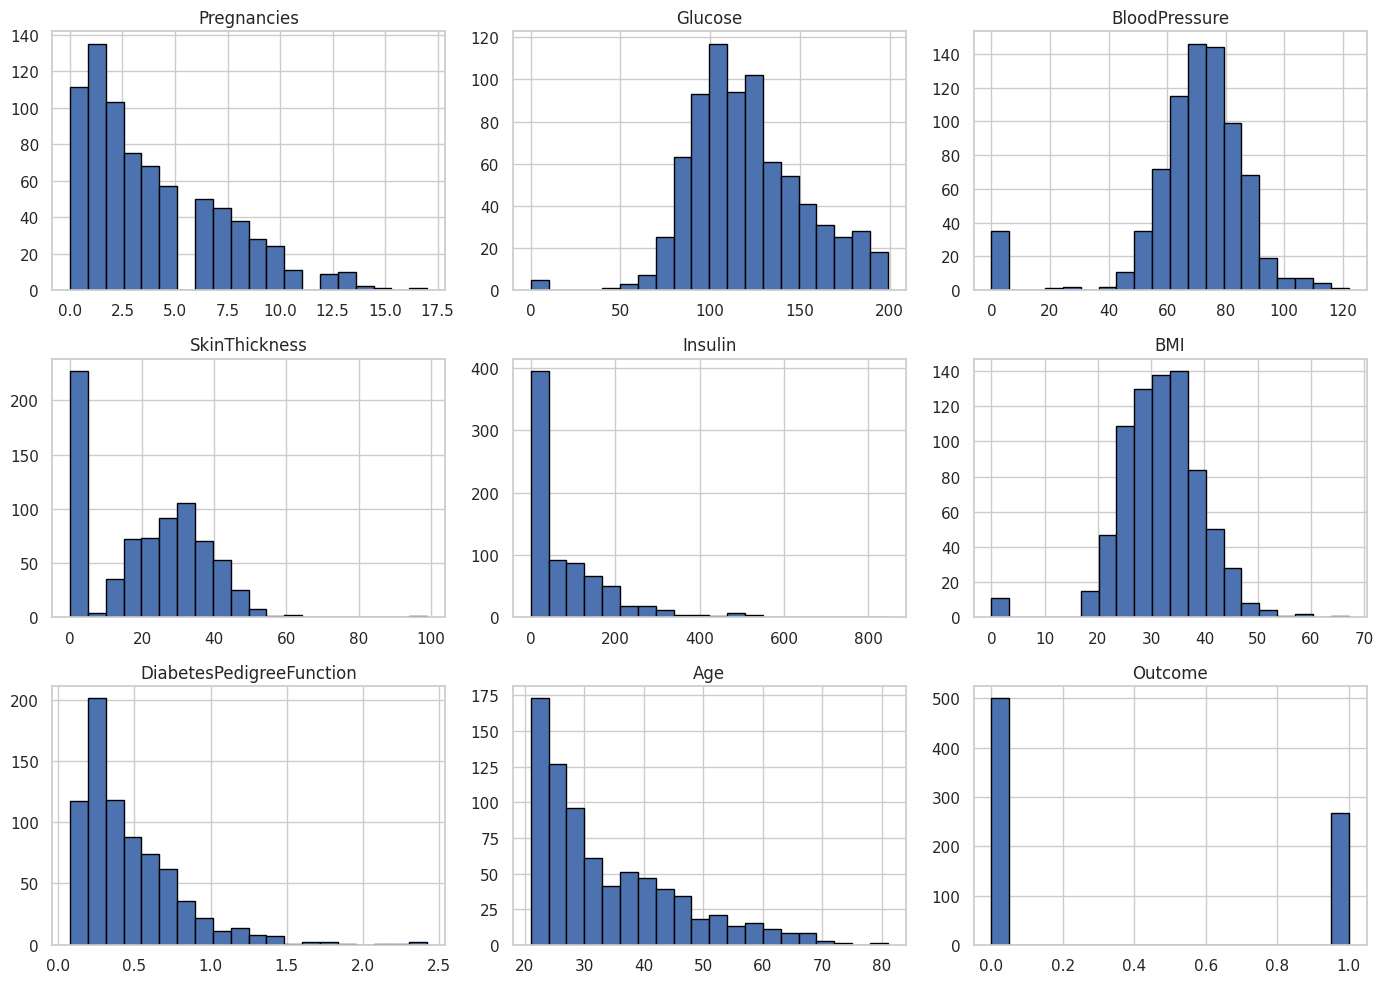

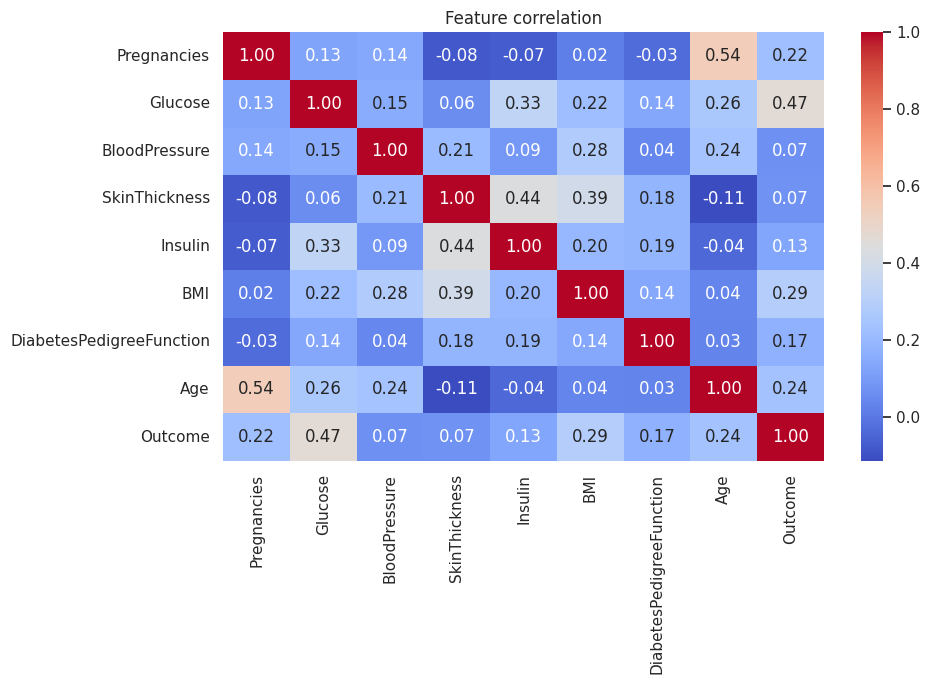

In [6]:
df.hist(figsize=(14,10), bins=20, edgecolor="black")
plt.tight_layout(); plt.show()
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation"); plt.tight_layout(); plt.show()

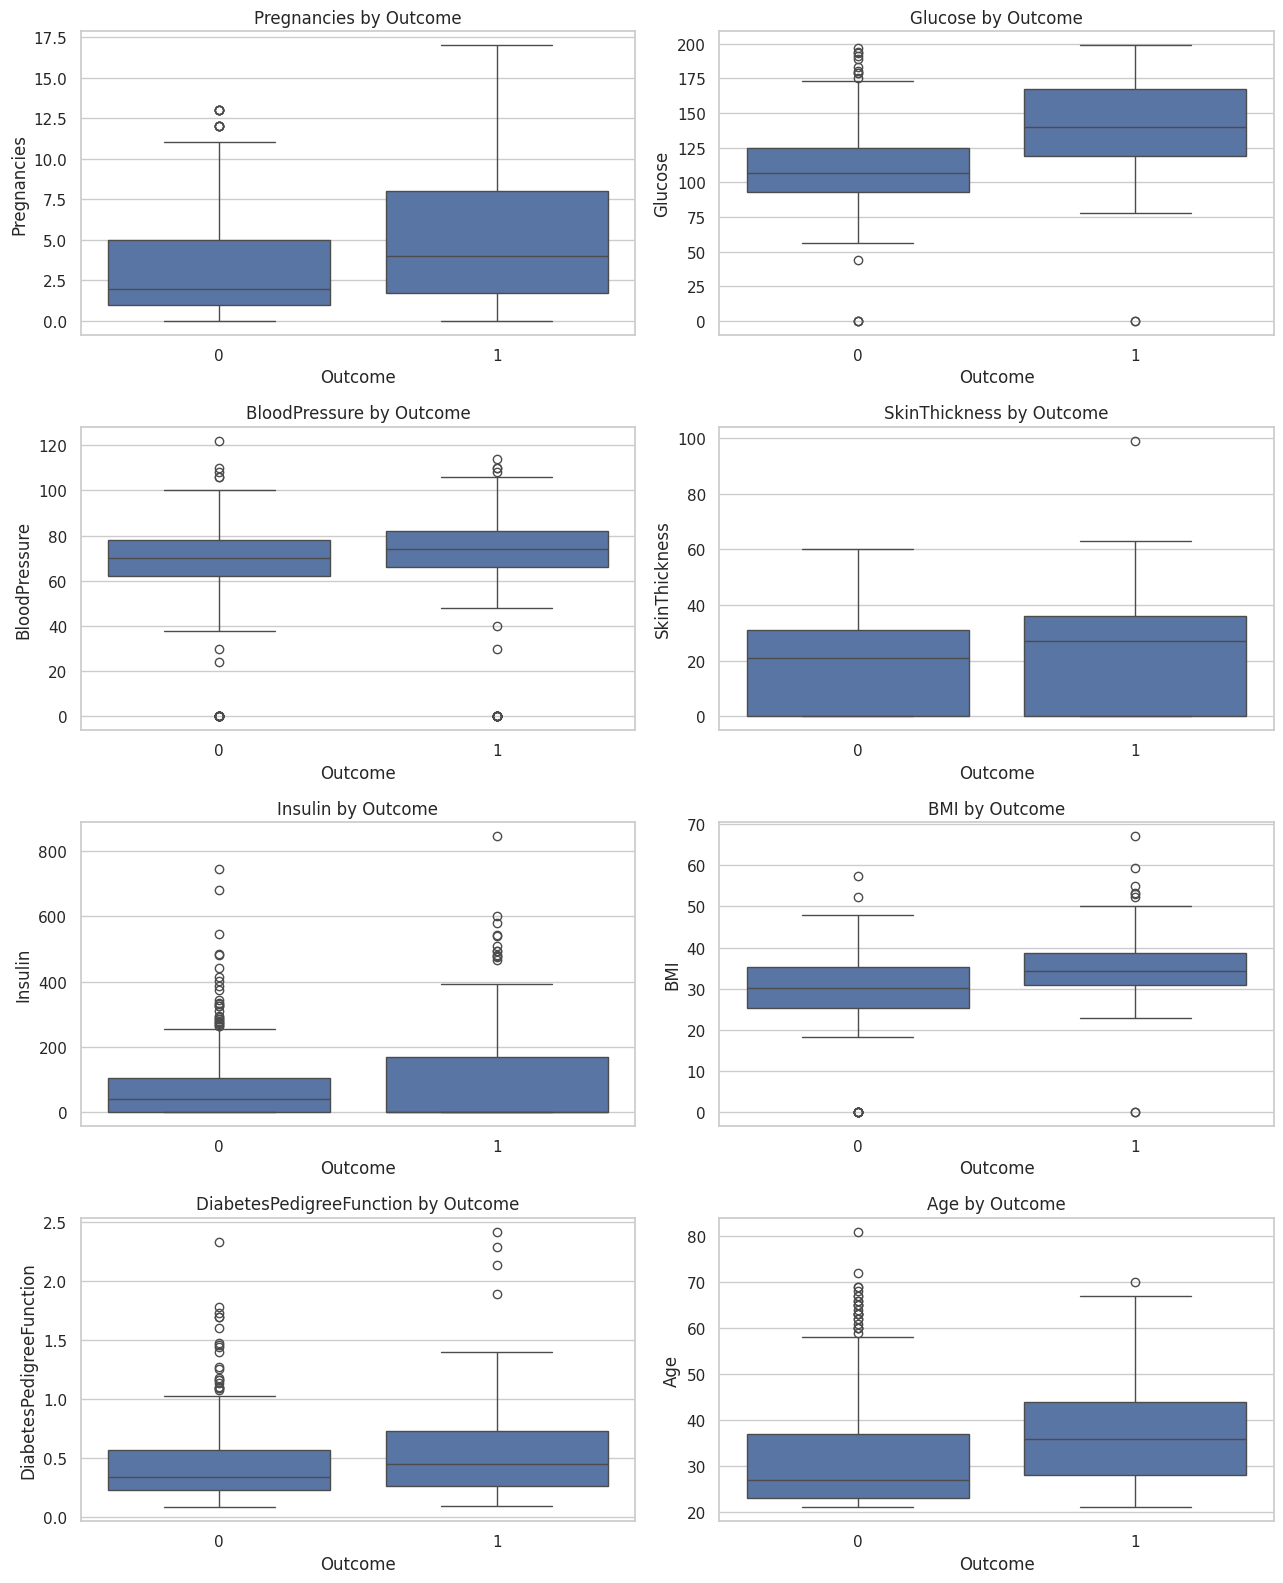

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(13,16))
for ax, col in zip(axes.flat, [c for c in df.columns if c != "Outcome"]):
    sns.boxplot(data=df, x="Outcome", y=col, ax=ax)
    ax.set_title(f"{col} by Outcome")
plt.tight_layout(); plt.show()

## EDA notes
Record the class distribution, invalid-zero counts, duplicate count, and any data-quality observations in your report. Do not replace zeros in this notebook.